# Recommendation System Project: IBM Community

In this notebook, you will be putting your recommendation skills to use on real data from the IBM Watson Studio platform. 


You may either submit your notebook through the workspace here, or you may work from your local machine and submit through the next page.  Either way assure that your code passes the project [RUBRIC](https://review.udacity.com/#!/rubrics/3325/view).  **Please save regularly.**

By following the table of contents, you will build out a number of different methods for making recommendations that can be used for different situations. 


## Table of Contents

I. [Exploratory Data Analysis](#Exploratory-Data-Analysis)<br>
II. [Rank Based Recommendations](#Rank)<br>
III. [User-User Based Collaborative Filtering](#User-User)<br>
IV. [Content Based Recommendations](#Content-Recs)<br>
V. [Matrix Factorization](#Matrix-Fact)<br>
VI. [Extras & Concluding](#conclusions)

At the end of the notebook, you will find directions for how to submit your work.  Let's get started by importing the necessary libraries and reading in the data.

In [40]:
# Import libraries and load a preview of the interaction data.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import project_tests as t


df = pd.read_csv(
    'data/user-item-interactions.csv', 
    dtype={'article_id': int, 'title': str, 'email': str}
)
# Show df to get an idea of the data
df.head()

,Unnamed: 0,article_id,title,email
0,0,1430,"using pixiedust for fast, flexible, and easier...",ef5f11f77ba020cd36e1105a00ab868bbdbf7fe7
1,1,1314,healthcare python streaming application demo,083cbdfa93c8444beaa4c5f5e0f5f9198e4f9e0b
2,2,1429,use deep learning for image classification,b96a4f2e92d8572034b1e9b28f9ac673765cd074
3,3,1338,ml optimization using cognitive assistant,06485706b34a5c9bf2a0ecdac41daf7e7654ceb7
4,4,1276,deploy your python model as a restful api,f01220c46fc92c6e6b161b1849de11faacd7ccb2


In [41]:
# Register the Inter fonts and apply the shared chart style.
from pathlib import Path
from matplotlib import font_manager

# Notebook working directory is starter/
font_dir = Path("../fonts")

if not font_dir.is_dir():
    raise FileNotFoundError(f"Font folder not found: {font_dir.resolve()}")

for font_file in font_dir.glob("*.ttf"):
    font_manager.fontManager.addfont(str(font_file))

plt.style.use("my_charts.mplstyle")

# Confirm that Matplotlib can find the font
print(font_manager.findfont("Inter", fallback_to_default=False))

C:\Users\agbro\Documents\ChatGPT\Udacity - Data Science Nano Degree\dsnd-recommendation-systems-project\fonts\Inter-VariableFont_opsz,wght.ttf


### <a class="anchor" id="Exploratory-Data-Analysis">Part I : Exploratory Data Analysis</a>

Use the dictionary and cells below to provide some insight into the descriptive statistics of the data.

`1.` Are there any missing values? If so, provide a count of missing values. If there are missing values in `email`, assign it the same id value `"unknown_user"`.

In [42]:
# Some interactions do not have a user associated with it, assume the same user.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45993 entries, 0 to 45992
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  45993 non-null  int64
 1   article_id  45993 non-null  int64
 2   title       45993 non-null  str  
 3   email       45976 non-null  str  
dtypes: int64(2), str(2)
memory usage: 1.4 MB


In [43]:
# Count interactions with missing user identifiers.
print(f"Number of null email values: {df['email'].isna().sum()}")

Number of null email values: 17


In [44]:
# Inspect interactions with missing user identifiers.
df[df.email.isna()]

,Unnamed: 0,article_id,title,email
25131,25146,1016,why you should master r (even if it might even...,NaN
29758,30157,1393,the nurse assignment problem,NaN
29759,30158,20,working interactively with rstudio and noteboo...,NaN
29760,30159,1174,breast cancer wisconsin (diagnostic) data set,NaN
29761,30160,62,data visualization: the importance of excludin...,NaN
35264,36016,224,"using apply, sapply, lapply in r",NaN
35276,36029,961,beyond parallelize and collect,NaN
35277,36030,268,sector correlations shiny app,NaN
35278,36031,268,sector correlations shiny app,NaN
35279,36032,268,sector correlations shiny app,NaN


In [45]:
# Fill email NaNs with "unknown_user"
df[df.email.isna()]
df.loc[df["email"].isna(), "email"] = "unknown_user"


In [46]:
# Check if no more NaNs 
df[df.email.isna()]

,Unnamed: 0,article_id,title,email


`2.` What is the distribution of how many articles a user interacts with in the dataset?  Provide a visual and descriptive statistics to assist with giving a look at the number of times each user interacts with an article.

count    5149.000000
mean        8.932414
std        16.801011
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       364.000000
Name: count, dtype: float64


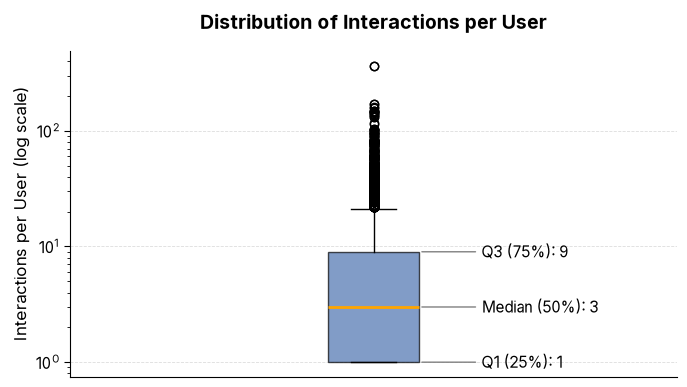

In [47]:
# What are the descriptive statistics of the number of articles a user interacts with?

interactions_per_user = df["email"].value_counts()
print(interactions_per_user.describe())

fig, ax = plt.subplots(figsize=(7, 4))

ax.boxplot(
    interactions_per_user,
    patch_artist=True,
    boxprops={
            'facecolor': plt.rcParams['axes.prop_cycle'].by_key()['color'][0],
            'edgecolor': 'black',
            'alpha': 0.7,
        },
    medianprops={"color": "orange", "linewidth": 2},
)

ax.set_title("Distribution of Interactions per User")
ax.set_xticks([])
ax.set_yscale("log")
ax.set_ylabel("Interactions per User (log scale)")

quartiles = interactions_per_user.quantile([0.25, 0.5, 0.75])

for name, value in zip(["Q1 (25%)", "Median (50%)", "Q3 (75%)"], quartiles):
    ax.annotate(
        f"{name}: {value:g}",
        xy=(1.075, value),  # Right edge of the default box
        xytext=(45, 0),
        textcoords="offset points",
        va="center",
        arrowprops={"arrowstyle": "-", "color": "gray"},
    )

plt.tight_layout()
plt.show()

The boxplot shows a median of 3 interactions per user. The first quartile (Q1) is 1 interaction, and the third quartile (Q3) is 9, meaning that at least 75% of users have 9 or fewer interactions. The mean of approximately 8.93 exceeds the median, reflecting the influence of highly active users. The maximum is 364 interactions per user.

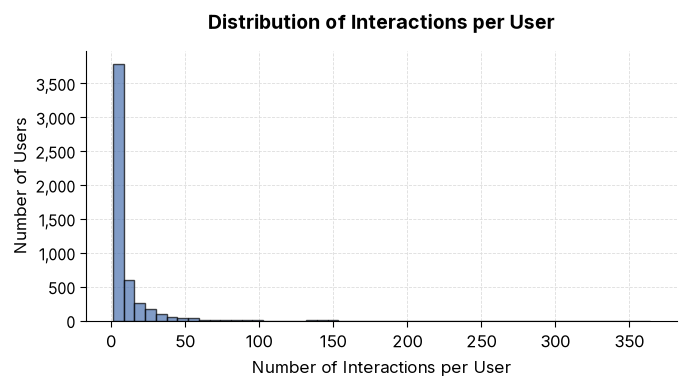

In [48]:
# Create a plot of the number of articles read by each user

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(interactions_per_user, bins=50, alpha=0.7)
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

ax.set_title("Distribution of Interactions per User")
ax.set_xlabel("Number of Interactions per User")
ax.set_ylabel("Number of Users")

plt.tight_layout()
plt.show()

The distribution of interactions per user is strongly right-skewed: most users have relatively few interactions, while a small number are highly active.

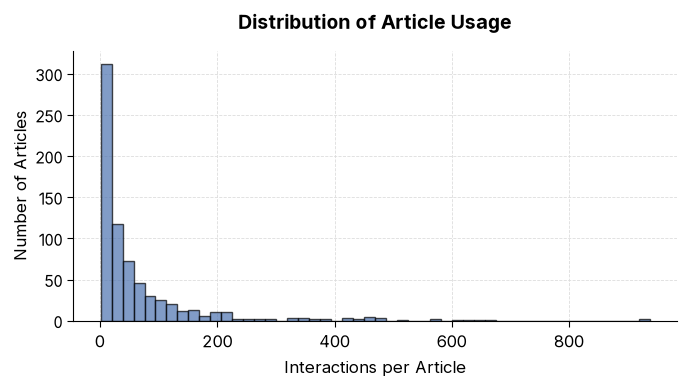

In [49]:
# Create a plot of the number of times each article was read
interactions_per_article = df["article_id"].value_counts()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(interactions_per_article, bins=50, alpha=0.7)
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

plt.xlabel('Interactions per Article')
plt.ylabel('Number of Articles')
plt.title('Distribution of Article Usage')
plt.show()

In [50]:
# Summarize article interaction counts and display the five most popular articles.
print(interactions_per_article.describe())
print(interactions_per_article.head())

count    714.000000
mean      64.415966
std      109.175923
min        1.000000
25%        8.000000
50%       25.000000
75%       69.000000
max      937.000000
Name: count, dtype: float64
article_id
1429    937
1330    927
1431    671
1427    643
1364    627
Name: count, dtype: int64


The distribution of article usage is strongly right-skewed: most articles receive relatively few interactions, while a small number receive many interactions.

In [51]:
# Fill in the median and maximum number of user_article interactions below
median_val = int(interactions_per_user.median())
max_views_by_user = int(interactions_per_user.max())

print(f"50% of users have {median_val} interactions or fewer.")
print(f"The maximum number of interactions by one user is {max_views_by_user}.")

50% of users have 3 interactions or fewer.
The maximum number of interactions by one user is 364.


`3.` Use the cells below to find:

**a.** The number of unique articles that have an interaction with a user.  
**b.** The number of unique articles in the dataset (whether they have any interactions or not).<br>
**c.** The number of unique users in the dataset. (excluding null values) <br>
**d.** The number of user-article interactions in the dataset.

In [52]:
# Count unique articles, users, and total interactions.
unique_articles = df["article_id"].nunique()
total_articles =  df["article_id"].nunique()
unique_users =  df["email"].nunique()
user_article_interactions =  len(df)

print(f"a. Number of unique articles with at least one interaction: {unique_articles}")
print(f"b. Number of unique articles in the dataset: {total_articles}")
print(f"c. Number of unique users: {unique_users:,}")
print(f"d. Total number of user-article interactions: {user_article_interactions:,}")

a. Number of unique articles with at least one interaction: 714
b. Number of unique articles in the dataset: 714
c. Number of unique users: 5,149
d. Total number of user-article interactions: 45,993


The unique user count includes one unknown_user, which groups the 17 interactions with missing email values.

`4.` Use the cells below to find the most viewed **article_id**, as well as how often it was viewed.  After talking to the company leaders, the `email_mapper` function was deemed a reasonable way to map users to ids.  There were a small number of null values, and it was found that all of these null values likely belonged to a single user (which is how they are stored using the function below).

In [53]:
# The most viewed article in the dataset as a string with one value following the decimal 
most_viewed_article_id =  int(interactions_per_article.idxmax())

print(interactions_per_article.head())
print(most_viewed_article_id)

# The most viewed article in the dataset was viewed how many times?
max_views = interactions_per_article.max()
print(max_views)

article_id
1429    937
1330    927
1431    671
1427    643
1364    627
Name: count, dtype: int64
1429
937


In [54]:
# No need to change the code here - this will be helpful for later parts of the notebook
# Run this cell to map the user email to a user_id column and remove the email column

def email_mapper(df=df):
    coded_dict = {
        email: num 
        for num, email in enumerate(df['email'].unique(), start=1)
    }
    return [coded_dict[val] for val in df['email']]

df['user_id'] = email_mapper(df)
del df['email']

# show header
df.head()

,Unnamed: 0,article_id,title,user_id
0,0,1430,"using pixiedust for fast, flexible, and easier...",1
1,1,1314,healthcare python streaming application demo,2
2,2,1429,use deep learning for image classification,3
3,3,1338,ml optimization using cognitive assistant,4
4,4,1276,deploy your python model as a restful api,5


In [55]:
## If you stored all your results in the variable names above, 
## you shouldn't need to change anything in this cell

sol_1_dict = {
    '`50% of individuals have _____ or fewer interactions.`': median_val,
    '`The total number of user-article interactions in the dataset is ______.`': user_article_interactions,
    '`The maximum number of user-article interactions by any 1 user is ______.`': max_views_by_user,
    '`The most viewed article in the dataset was viewed _____ times.`': max_views,
    '`The article_id of the most viewed article is ______.`': most_viewed_article_id,
    '`The number of unique articles that have at least 1 rating ______.`': unique_articles,
    '`The number of unique users in the dataset is ______`': unique_users,
    
    # Here, total_articles counts articles in the supplied dataset, not the entire IBM platform.
    '`The number of unique articles on the IBM platform`': total_articles
}

# Test your dictionary against the solution
t.sol_1_test(sol_1_dict)

It looks like you have everything right here! Nice job!


### Summary: Exploratory Data Analysis

The dataset contains **45,993 user–article interactions** involving **5,149 user identifiers**, including one `unknown_user` grouping the 17 interactions with missing email values. All **714 unique articles** in the supplied dataset have at least one recorded interaction, so the counts of observed articles and total available articles are identical; this does not establish the size of the entire IBM platform’s catalog. User activity is strongly right-skewed: the **median is 3 interactions per user**, while the most active user recorded **364**. These counts include repeat interactions with the same article.

Article usage is also strongly right-skewed. The most-viewed article, **ID 1429**, received **937 interactions**. This concentration makes popularity a useful starting point for recommendations, particularly for users with no history. However, popularity alone cannot capture individual interests, and the limited history of many users may constrain collaborative filtering. The following sections therefore explore personalized and content-based alternatives. Because the data record interactions rather than explicit ratings, these methods will identify patterns of engagement rather than directly measure user satisfaction.

### <a class="anchor" id="Rank">Part II: Rank-Based Recommendations</a>

In this project, we don't actually have ratings for whether a user liked an article or not.  We only know that a user has interacted with an article. In these cases, the popularity of an article can really only be based on how often an article was interacted with.

`1.` Fill in the function below to return the **n** top articles ordered with most interactions as the top. Test your function using the tests below.

In [56]:
# The first function returns the top 'n' articles (with the most interactions).
# The second function returns the corresponding article IDs.

def get_top_articles(n, df=df):
    """
    INPUT:
    n - (int) the number of top articles to return
    df - (pandas dataframe) df as defined at the top of the notebook 
    
    OUTPUT:
    top_articles - (list) A list of the top 'n' article titles 
    
    """
    top_ids = df["article_id"].value_counts()[:n]

    top_articles = [
    df.loc[df["article_id"] == article_id, "title"].iloc[0]
    for article_id in top_ids.index
    ]
    
    return top_articles # Return the top article titles from df

def get_top_article_ids(n, df=df):
    """
    INPUT:
    n - (int) the number of top articles to return
    df - (pandas dataframe) df as defined at the top of the notebook 
    
    OUTPUT:
    top_articles - (list) A list of the top 'n' article titles 
    
    """
    top_articles = df["article_id"].value_counts().index[:n].tolist()
 
    return top_articles # Return the top article ids

In [57]:
print(get_top_articles(10))
print(get_top_article_ids(10))

['use deep learning for image classification', 'insights from new york car accident reports', 'visualize car data with brunel', 'use xgboost, scikit-learn & ibm watson machine learning apis', 'predicting churn with the spss random tree algorithm', 'healthcare python streaming application demo', 'finding optimal locations of new store using decision optimization', 'apache spark lab, part 1: basic concepts', 'analyze energy consumption in buildings', 'gosales transactions for logistic regression model']
[1429, 1330, 1431, 1427, 1364, 1314, 1293, 1170, 1162, 1304]


In [58]:
# Test your function by returning the top 5, 10, and 20 articles
top_5 = get_top_articles(5)
top_10 = get_top_articles(10)
top_20 = get_top_articles(20)

# Test each of your three lists from above
t.sol_2_test(get_top_articles)

Your top_5 looks like the solution list! Nice job.
Your top_10 looks like the solution list! Nice job.
Your top_20 looks like the solution list! Nice job.


### Summary: Rank-Based Recommendations

We ranked articles by their **total number of recorded interactions** and created functions to return the top *n* article IDs and corresponding titles in order of descending popularity. Repeated interactions count toward popularity; these counts indicate engagement, not necessarily satisfaction or the number of distinct readers.

This approach provides a simple **baseline and a fallback for new users**, since it requires no personal interaction history. However, it gives everyone the same recommendations and favors already-popular articles.

### <a class="anchor" id="User-User">Part III: User-User Based Collaborative Filtering</a>


`1.` Use the function below to reformat the **df** dataframe to be shaped with users as the rows and articles as the columns.  

* Each **user** should only appear in each **row** once.


* Each **article** should only show up in one **column**.  


* **If a user has interacted with an article, then place a 1 where the user-row meets for that article-column**.  It does not matter how many times a user has interacted with the article, all entries where a user has interacted with an article should be a 1.  


* **If a user has not interacted with an item, then place a zero where the user-row meets for that article-column**. 

Use the tests to make sure the basic structure of your matrix matches what is expected by the solution.

In [59]:
df.head()

,Unnamed: 0,article_id,title,user_id
0,0,1430,"using pixiedust for fast, flexible, and easier...",1
1,1,1314,healthcare python streaming application demo,2
2,2,1429,use deep learning for image classification,3
3,3,1338,ml optimization using cognitive assistant,4
4,4,1276,deploy your python model as a restful api,5


In [60]:
# create the user-article matrix with 1's and 0's

def create_user_item_matrix(df, fill_value=0):
    """
    INPUT:
    df - pandas dataframe with article_id, title, user_id columns
    
    OUTPUT:
    user_item - user item matrix 
    
    Description:
    Return a matrix with user ids as rows and article ids on the columns with 1 values where a user interacted with 
    an article and a 0 otherwise
    """
    interaction_counts = df.groupby(["user_id", "article_id"]).size()

    user_item = (interaction_counts.gt(0).astype(int).unstack(fill_value=fill_value))

    return user_item # return the user_item matrix 


user_item = create_user_item_matrix(df)

In [61]:
user_item.head()

article_id,0,2,4,8,9,12,14,15,16,18,...,1434,1435,1436,1437,1439,1440,1441,1442,1443,1444
user_id,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [62]:
## Tests: You should just need to run this cell.  Don't change the code.
assert user_item.shape[0] == 5149, "Oops!  The number of users in the user-article matrix doesn't look right."
assert user_item.shape[1] == 714, "Oops!  The number of articles in the user-article matrix doesn't look right."
assert user_item.sum(axis=1)[1] == 36, "Oops!  The number of articles seen by user 1 doesn't look right."
print("You have passed our quick tests!  Please proceed!")

You have passed our quick tests!  Please proceed!


`2.` Complete the function below which should take a user_id and provide an ordered list of the most similar users to that user (from most similar to least similar).  The returned result should not contain the provided user_id, as we know that each user is similar to him/herself. Because the results for each user here are binary, it (perhaps) makes sense to compute similarity as the dot product of two users. 

Use the tests to test your function.

In [63]:
# Lets use the cosine_similarity function from sklearn
from sklearn.metrics.pairwise import cosine_similarity

In [64]:
def find_similar_users(user_id, user_item=user_item, include_similarity=False):
    """
    INPUT:
    user_id - (int) a user_id
    user_item - (pandas dataframe) matrix of users by articles: 
                1's when a user has interacted with an article, 0 otherwise
    include_similarity - (bool) whether to include the similarity in the output
    
    OUTPUT:
    similar_users - (list) an ordered list where the closest users (largest dot product users)
                    are listed first
    
    Description:
    Computes the similarity of every pair of users based on the dot product
    Returns an ordered list of user ids. If include_similarity is True, returns a list of lists
    where the first element is the user id and the second the similarity.
    
    """
    
    # compute similarity of each user to the provided user
    idx = user_item.index.get_loc(user_id)
    cos_sim = cosine_similarity(user_item, user_item)
    scores = list(enumerate(cos_sim[idx]))

    # sort by similarity
    # remove the own user's id
    scores = [pair for pair in scores if pair[0] != idx]
    scores = sorted(scores, key=lambda x: x[1], reverse=True)

    # create list of just the ids
    sim_users = [i[0] for i in scores]

    # create list of just the similarities
    sims = [i[1] for i in scores]
    most_similar_users = user_item.index[sim_users].tolist()
    
    if include_similarity:
        return [[a, b] for a, b in zip(most_similar_users, sims)] # return a list of lists with [[similar_user_id, similarity], ...]

    return most_similar_users # return a list of the users in order from most to least similar

In [65]:
# Do a spot check of your function
print("The 10 most similar users to user 1 are: {}".format(find_similar_users(1)[:10]))
print("The 5 most similar users to user 3933 are: {}".format(find_similar_users(3933)[:5]))
print("The 3 most similar users to user 46 are: {}".format(find_similar_users(46)[:3]))

The 10 most similar users to user 1 are: [3933, 46, 4201, 253, 824, 5034, 5041, 136, 2305, 395]
The 5 most similar users to user 3933 are: [1, 46, 4201, 253, 824]
The 3 most similar users to user 46 are: [4201, 790, 5077]


`3.` Now that you have a function that provides the most similar users to each user, you will want to use these users to find articles you can recommend.  Complete the functions below to return the articles you would recommend to each user. 

In [66]:
def get_article_names(article_ids, df=df):
    """
    INPUT:
    article_ids - (list) a list of article ids
    df - (pandas dataframe) df as defined at the top of the notebook
    
    OUTPUT:
    article_names - (list) a list of article names associated with the list of article ids 
                    (this is identified by the title column in df)
    """
    # Your code here
    
    article_names = [
        df.loc[df["article_id"] == article_id, "title"].iloc[0]
        for article_id in article_ids
    ]

    return article_names # Return the article names associated with list of article ids


def get_ranked_article_unique_counts(article_ids, user_item=user_item):
    """
    INPUT:
    article_ids - (list) a list of article ids to evaluate (a subset to rank).
                the dtype should match the column labels in `user_item`.
    user_item - (pandas dataframe) a binary matrix of users by articles [n_users x n_articles]:
                1's when a user has interacted with an article, 0 otherwise 
                columns are article IDs.
    
    OUTPUT:
    ranked_article_unique_counts - (list) a list of tuples [(article_id, unique_user_count)]
                     only for the provided `article_ids` with article_id and number of unique
                     users that have interacted with the article, sorted by the number of unique
                     users in descending order
    
    Description:
    For each `article_id` in the input list, count the number of unique users who
    interacted with it (column sum in the binary `user_item` matrix).
    Return the (article_id, count) pairs sorted in descending order.
    """
    # Your code here

    article_unique_counts = []

    for article_id in article_ids:
        article_unique_count = int(user_item[article_id].sum())
        article_unique_counts.append([article_id, article_unique_count])

    ranked_article_unique_counts = sorted(article_unique_counts, key=lambda pair: pair[1], reverse=True)

    return ranked_article_unique_counts



def get_user_articles(user_id, user_item=user_item):
    """
    INPUT:
    user_id - (int) a user id
    user_item - (pandas dataframe) matrix of users by articles: 
                1's when a user has interacted with an article, 0 otherwise
    
    OUTPUT:
    article_ids - (list) a list of the article ids seen by the user
    article_names - (list) a list of article names associated with the list of article ids 
                    (this is identified by the title column in df)
    
    Description:
    Provides a list of the article_ids and article titles that have been seen by a user
    """
    # Your code here
    
    user_row = user_item.loc[user_id]
    article_ids = user_row[user_row == 1].index.tolist()
    article_names = get_article_names(article_ids)

    return article_ids, article_names # return the ids and names



def user_user_recs(user_id, m=10):
    """
    INPUT:
    user_id - (int) a user id
    m - (int) the number of recommendations you want for the user
    
    OUTPUT:
    recs - (list) a list of recommendations for the user
    
    Description:
    Loops through the users based on closeness to the input user_id
    For each user - finds articles the user hasn't seen before and provides them as recs
    Does this until m recommendations are found
    
    Notes:
    Users who are the same closeness are chosen arbitrarily as the 'next' user
    
    For the user where the number of recommended articles starts below m 
    and ends exceeding m, the last items are chosen arbitrarily
    
    """
    # Your code here
    
    similar_users = find_similar_users(user_id=user_id, user_item=user_item, include_similarity=False)
    seen_by_user, _ = get_user_articles(user_id=user_id, user_item=user_item)
    recs = []

    if m <= 0:
        return recs

    for similar_user in similar_users:
        seen_by_similar_user, _ = get_user_articles(similar_user)
        
        for article_id in seen_by_similar_user:
            if article_id not in seen_by_user and article_id not in recs:
                recs.append(article_id)
                if len(recs) == m:

                    return recs
                
    return recs # return your recommendations for this user_id    

In [67]:
# Check Results
get_article_names(user_user_recs(1, 10)) # Return 10 recommendations for user 1

['this week in data science (april 18, 2017)',
 'this week in data science (may 2, 2017)',
 'top 20 r machine learning and data science packages',
 'improving the roi of big data and analytics through leveraging new sources of data',
 'using apply, sapply, lapply in r',
 'awesome deep learning papers',
 'leverage python, scikit, and text classification for behavioral profiling',
 'challenges in deep learning',
 'do i need to learn r?',
 'how can data scientists collaborate to build better business']

In [68]:
get_ranked_article_unique_counts([1320, 232, 844])

[[1320, 123], [844, 78], [232, 62]]

In [69]:
# Test your functions here - No need to change this code - just run this cell
assert set(get_article_names([1024, 1176, 1305, 1314, 1422, 1427])) == set(['using deep learning to reconstruct high-resolution audio', 'build a python app on the streaming analytics service', 'gosales transactions for naive bayes model', 'healthcare python streaming application demo', 'use r dataframes & ibm watson natural language understanding', 'use xgboost, scikit-learn & ibm watson machine learning apis']), "Oops! Your the get_article_names function doesn't work quite how we expect."
assert set(get_article_names([1320, 232, 844])) == set(['housing (2015): united states demographic measures','self-service data preparation with ibm data refinery','use the cloudant-spark connector in python notebook']), "Oops! Your the get_article_names function doesn't work quite how we expect."
assert set(get_user_articles(20)[0]) == set([1320, 232, 844])
assert set(get_user_articles(20)[1]) == set(['housing (2015): united states demographic measures', 'self-service data preparation with ibm data refinery','use the cloudant-spark connector in python notebook'])
assert set(get_user_articles(2)[0]) == set([1024, 1176, 1305, 1314, 1422, 1427])
assert set(get_user_articles(2)[1]) == set(['using deep learning to reconstruct high-resolution audio', 'build a python app on the streaming analytics service', 'gosales transactions for naive bayes model', 'healthcare python streaming application demo', 'use r dataframes & ibm watson natural language understanding', 'use xgboost, scikit-learn & ibm watson machine learning apis'])
assert get_ranked_article_unique_counts([1320, 232, 844])[0] == [1320, 123], "Oops! Your the get_ranked_article_unique_counts function doesn't work quite how we expect.\nMake sure you are using the user_item matrix to create the article counts."
print("If this is all you see, you passed all of our tests!  Nice job!")

If this is all you see, you passed all of our tests!  Nice job!


`4.` Now we are going to improve the consistency of the **user_user_recs** function from above.  

* Instead of arbitrarily choosing when we obtain users who are all the same closeness to a given user - choose the users that have the most total article interactions before choosing those with fewer article interactions.


* Instead of arbitrarily choosing articles from the user where the number of recommended articles starts below m and ends exceeding m, choose articles with the articles with the most total interactions before choosing those with fewer total interactions. This ranking should be  what would be obtained from the **top_articles** function you wrote earlier.

In [70]:
def get_top_sorted_users(user_id, user_item=user_item):
    """
    INPUT:
    user_id - (int)
    user_item - (pandas dataframe) matrix of users by articles: 
            1's when a user has interacted with an article, 0 otherwise
    
            
    OUTPUT:
    neighbors_df - (pandas dataframe) a dataframe with:
                    neighbor_id - is a neighbor user_id
                    similarity - measure of the similarity of each user to the provided user_id
                    num_interactions - the number of articles viewed by the user
                    
    Other Details - sort the neighbors_df by the similarity and then by number of interactions where 
                    highest of each is higher in the dataframe, i.e. Descending order
     
    """
    # Your code here
    # Hint: find similar users, but include their similarity, from there we can find the number of interactions for each neighbor  

    similar_users = find_similar_users(
        user_id,
        user_item=user_item,
        include_similarity=True,
    )

    rows = []

    for neighbor_id, similarity in similar_users:
        seen_by_neighbor, _ = get_user_articles(
            neighbor_id,
            user_item=user_item,
        )
        num_interactions = len(seen_by_neighbor)

        rows.append([neighbor_id, similarity, num_interactions])

    neighbors_df = pd.DataFrame(
        rows,
        columns=["neighbor_id", "similarity", "num_interactions"],
    )

    neighbors_df = neighbors_df.sort_values(
        by=["similarity", "num_interactions"],
        ascending=[False, False],
    )

    return neighbors_df  # Return the dataframe specified in the doc_string



def user_user_recs_part2(user_id, m=10):
    """
    INPUT:
    user_id - (int) a user id
    m - (int) the number of recommendations you want for the user
    
    OUTPUT:
    recs - (list) a list of recommendations for the user by article id
    rec_names - (list) a list of recommendations for the user by article title
    
    Description:
    Loops through the users based on closeness to the input user_id
    For each user - finds articles the user hasn't seen before and provides them as recs
    Does this until m recommendations are found
    
    Notes:
    * Choose the users that have the most total article interactions 
    before choosing those with fewer article interactions.

    * Choose articles with the articles with the most total interactions 
    before choosing those with fewer total interactions. 
   
    """
    # Your code here

    art_ids_seen_u, art_names_seen_u = get_user_articles(user_id=user_id, user_item=user_item)
    neighbors_df = get_top_sorted_users(user_id, user_item=user_item)
    top_articles = get_top_article_ids(df["article_id"].nunique(), df=df)

    recs = []

    if m <= 0:
        return recs, get_article_names(recs)

    for neighbor in neighbors_df["neighbor_id"]:
        art_ids_seen_n, _ = get_user_articles(neighbor, user_item=user_item)

        for art in top_articles:
            if (
                art in art_ids_seen_n
                and art not in art_ids_seen_u
                and art not in recs
            ):
                recs.append(art)

                if len(recs) == m:
                    return recs, get_article_names(recs)

    return recs, get_article_names(recs) # return your recommendations for this user_id

In [71]:
# Quick spot check - don't change this code - just use it to test your functions
rec_ids, rec_names = user_user_recs_part2(20, 10)
print("The top 10 recommendations for user 20 are the following article ids:")
print(rec_ids)
print()
print("The top 10 recommendations for user 20 are the following article names:")
print(rec_names)

The top 10 recommendations for user 20 are the following article ids:
[1293, 1162, 1185, 1165, 254, 1271, 1328, 1410, 40, 1402]

The top 10 recommendations for user 20 are the following article names:
['finding optimal locations of new store using decision optimization', 'analyze energy consumption in buildings', 'classify tumors with machine learning', 'analyze precipitation data', 'apple, ibm add machine learning to partnership with watson-core ml coupling', 'customer demographics and sales', 'income (2015): united states demographic measures', 'uci: sms spam collection', 'ensemble learning to improve machine learning results', 'uci: adult - predict income']


`5.` Use your functions from above to correctly fill in the solutions to the dictionary below.  Then test your dictionary against the solution.  Provide the code you need to answer each following the comments below.

In [72]:
print(get_top_sorted_users(1, user_item=user_item).head(n=1))
print(get_top_sorted_users(2, user_item=user_item).head(n=10))
print(get_top_sorted_users(131, user_item=user_item).head(n=10))

   neighbor_id  similarity  num_interactions
0         3933    0.986013                35
    neighbor_id  similarity  num_interactions
0          5083    0.730297                 5
1          1552    0.577350                 2
2          1890    0.577350                 2
3          1372    0.471405                 3
4          2941    0.433013                 8
37         3586    0.408248                 4
5           331    0.408248                 1
6           348    0.408248                 1
7           378    0.408248                 1
8           496    0.408248                 1
   neighbor_id  similarity  num_interactions
0         3870    0.986667                75
1          203    0.388909                96
2         4459    0.388909                96
3         3782    0.387585               135
4           40    0.384308                52
5         4932    0.384308                52
6           23    0.377647               135
7          242    0.375823                59

In [73]:
### Tests with a dictionary of results
user1_most_sim = 3933 # Find the user that is most similar to user 1 
user2_6th_sim = 3586 # Find the 6th most similar user to user 2
user131_10th_sim = 383 # Find the 10th most similar user to user 131

In [74]:
## Dictionary Test Here
sol_5_dict = {
    'The user that is most similar to user 1.': user1_most_sim, 
    'The user that is the 6th most similar to user 2.': user2_6th_sim,
    'The user that is the 10th most similar to user 131.': user131_10th_sim,
}

t.sol_5_test(sol_5_dict)

This all looks good!  Nice job!


`6.` If we were given a new user, which of the above functions would you be able to use to make recommendations?  Explain.  Can you think of a better way we might make recommendations?  Use the cell below to explain a better method for new users.

**Your response here:**
For new users, we could use `get_top_article_ids(n, df=df)` to recommend the most popular articles. This approach does not require a user’s interaction history.

`7.` Using your existing functions, provide the top 10 recommended articles you would provide for the a new user below.  You can test your function against our thoughts to make sure we are all on the same page with how we might make a recommendation.

In [75]:
# What would your recommendations be for this new user 0?  As a new user, they have no observed articles.
# Provide a list of the top 10 article ids you would give to 
new_user_recs = get_top_article_ids(n=10, df=df)

print(f"Recommended article IDs: {new_user_recs}") # Your recommendations here

Recommended article IDs: [1429, 1330, 1431, 1427, 1364, 1314, 1293, 1170, 1162, 1304]


In [76]:
assert set(new_user_recs) == {1314, 1429, 1293, 1427, 1162, 1364, 1304, 1170, 1431, 1330}, "Oops!  It makes sense that in this case we would want to recommend the most popular articles, because we don't know anything about these users."

print("That's right!  Nice job!")

That's right!  Nice job!


### Summary: User-User Collaborative Filtering

We created a **binary user–article matrix** and used **cosine similarity** to identify users with similar interaction histories. Recommendations draw on articles those neighbors have seen, excluding articles the target user has already encountered and avoiding duplicate suggestions. We refined the ordering by using neighbors’ distinct-article counts to break similarity ties and **total article interaction counts** to prioritize eligible articles.

This approach personalizes recommendations using shared behavior rather than overall popularity alone. However, limited interaction histories can make similarities less informative, and users with no history cannot yet receive collaborative recommendations. For these **new users**, we use popularity-based recommendations as a fallback.

### <a class="anchor" id="Content-Recs">Part IV: Content Based Recommendations</a>

Another method we might use to make recommendations is to recommend similar articles that are possibly related. One way we can find article relationships is by clustering text about those articles.  Let's consider content to be the article **title**, as it is the only text we have available. One point to highlight, there isn't one way to create a content based recommendation, especially considering that text information can be processed in many ways.  

`1.` Use the function bodies below to create a content based recommender function `make_content_recs`. We'll use TF-IDF to create a matrix based off article titles, and use this matrix to create clusters of related articles. You can use this function to make recommendations of new articles.

In [77]:
df.head()

,Unnamed: 0,article_id,title,user_id
0,0,1430,"using pixiedust for fast, flexible, and easier...",1
1,1,1314,healthcare python streaming application demo,2
2,2,1429,use deep learning for image classification,3
3,3,1338,ml optimization using cognitive assistant,4
4,4,1276,deploy your python model as a restful api,5


In [78]:
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.decomposition import TruncatedSVD

In [79]:
# unique articles
# Create one row per article, retaining its ID and title.
df_unique_articles = (
    df[["article_id", "title"]]
    .drop_duplicates(subset="article_id")
    .reset_index(drop=True)
)

print(df_unique_articles.head())

   article_id                                              title
0        1430  using pixiedust for fast, flexible, and easier...
1        1314       healthcare python streaming application demo
2        1429         use deep learning for image classification
3        1338          ml optimization using cognitive assistant
4        1276          deploy your python model as a restful api


In [80]:
# Create a vectorizer using TfidfVectorizer and fit it to the article titles
max_features = 200
max_df = 0.75
min_df = 5

vectorizer = TfidfVectorizer(
    max_df=max_df,
    min_df=min_df,
    stop_words="english",
    max_features=max_features,
)
print("Running TF-IDF")
X_tfidf = vectorizer.fit_transform(df_unique_articles["title"]) # Fit the vectorizer to the article titles

print(f"n_samples: {X_tfidf.shape[0]}, n_features: {X_tfidf.shape[1]}")

lsa = make_pipeline(TruncatedSVD(n_components=50), Normalizer(copy=False))
X_lsa = lsa.fit_transform(X_tfidf) # Fit the LSA model to the vectorized article titles
explained_variance = lsa[0].explained_variance_ratio_.sum()

print(f"Explained variance of the SVD step: {explained_variance * 100:.1f}%")

Running TF-IDF
n_samples: 714, n_features: 125
Explained variance of the SVD step: 76.0%


Text(0.5, 0, 'Number of clusters')

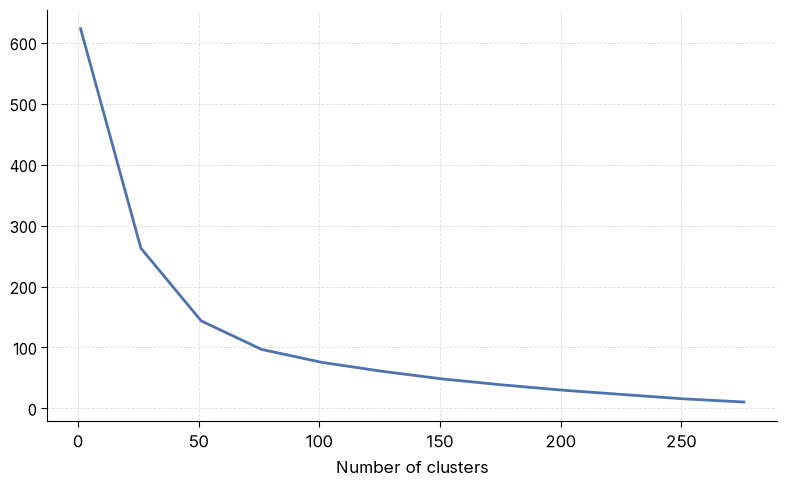

In [81]:
# Let's map the inertia for different number of clusters to find the optimal number of clusters
# We'll plot it to see the elbow
inertia = []
clusters = 300
step = 25
max_iter = 50
n_init = 5
random_state = 42
for k in range(1, clusters, step):
    kmeans = KMeans(
        n_clusters=k,
        max_iter=max_iter,
        n_init=n_init,
        random_state=random_state,
    ).fit(X_lsa)
    # inertia is the sum of squared distances to the closest cluster center
    inertia.append(kmeans.inertia_)
plt.plot(range(1, clusters, step), inertia)
plt.xlabel('Number of clusters')

There appears to be an elbow about 50, so we'll use 50 clusters.

In [82]:
n_clusters = 50 # Number of clusters
kmeans = KMeans(
    # Your code here, same as parameters above
    n_clusters=n_clusters,
    max_iter=max_iter,
    n_init=n_init,
    random_state=random_state,
    ).fit(X_lsa)

In [83]:
# create a new column `title_cluster` and assign it the kmeans cluster labels
# First we need to map the labels to df_unique_articles article ids and then apply those to df
article_cluster_map = article_cluster_map = dict(
    zip(df_unique_articles["article_id"], kmeans.labels_)
) # Map article_id to cluster label

df["title_cluster"] = df["article_id"].map(article_cluster_map) # apply map to create title clusters

In [84]:
# Let's check the number of articles in each cluster
np.array(np.unique(kmeans.labels_, return_counts=True)).T

array([[ 0, 12],
       [ 1, 20],
       [ 2, 23],
       [ 3, 29],
       [ 4,  9],
       [ 5, 20],
       [ 6, 15],
       [ 7, 19],
       [ 8,  8],
       [ 9, 21],
       [10, 28],
       [11, 68],
       [12, 27],
       [13, 12],
       [14, 17],
       [15, 37],
       [16, 14],
       [17,  7],
       [18, 21],
       [19,  8],
       [20, 11],
       [21,  7],
       [22,  1],
       [23, 38],
       [24,  9],
       [25, 13],
       [26, 10],
       [27,  7],
       [28, 10],
       [29,  8],
       [30,  7],
       [31, 11],
       [32, 11],
       [33, 11],
       [34, 10],
       [35,  5],
       [36,  8],
       [37,  7],
       [38,  8],
       [39, 20],
       [40, 12],
       [41,  3],
       [42,  5],
       [43,  7],
       [44,  9],
       [45, 14],
       [46,  8],
       [47,  9],
       [48, 10],
       [49, 10]])

In [85]:
print(df.head())

   Unnamed: 0  article_id                                              title  \
0           0        1430  using pixiedust for fast, flexible, and easier...   
1           1        1314       healthcare python streaming application demo   
2           2        1429         use deep learning for image classification   
3           3        1338          ml optimization using cognitive assistant   
4           4        1276          deploy your python model as a restful api   

   user_id  title_cluster  
0        1              7  
1        2             29  
2        3             18  
3        4              7  
4        5             16  


In [86]:
def get_similar_articles(article_id, df=df):
    """
    INPUT:
    article_id - (int) an article id 
    df - (pandas dataframe) df as defined at the top of the notebook 
    
    OUTPUT:
    article_ids - (list) a list of article ids that are in the same title cluster
    
    Description:
    Returns a list of the article ids that are in the same title cluster
    """
     # Your code here

    title_cluster = df.loc[
        df["article_id"] == article_id, "title_cluster"
    ].iloc[0]

    articles_in_cluster = df.loc[
        (df["title_cluster"] == title_cluster)
        & (df["article_id"] != article_id),
        "article_id",
    ].unique().tolist()

    return articles_in_cluster

In [87]:
def make_content_recs(article_id, n, df=df):
    """
    INPUT:
    article_id - (int) an article id
    n - (int) the number of recommendations you want similar to the article id
    df - (pandas dataframe) df as defined at the top of the notebook
    
    OUTPUT:
    n_ranked_similar_articles - (list) a list of article ids that are in the same title cluster ranked
                                by popularity
    n_ranked_article_names - (list) a list of article names associated with the list of article ids
    
    Description:
    Returns a list of the n most ranked similar articles to a given article_id based on the title
    cluster in df. Rank similar articles using the function get_ranked_article_unique_counts.
    """
    # Your code here

    all_similar = get_similar_articles(article_id, df=df)
    ranked_all_similar = get_ranked_article_unique_counts(all_similar, user_item=user_item)

    n_ranked_similar_articles = [article_id for article_id, _ in ranked_all_similar[:n]]
    n_ranked_article_names = get_article_names(n_ranked_similar_articles, df=df)

    return n_ranked_similar_articles, n_ranked_article_names

In [88]:
# Test out your content recommendations given artice_id 25
rec_article_ids, rec_article_titles = make_content_recs(25, 10)
print(rec_article_ids)
print(rec_article_titles)

[1025, 237, 593, 349, 101, 821, 975, 766, 508, 464]
['data tidying in data science experience', 'deep learning with data science experience', 'upload files to ibm data science experience using the command line', 'ibm data science experience white paper - sparkr transforming r into a tool for big data analytics', 'how to choose a project to practice data science', 'using rstudio in ibm data science experience', 'the data science process', 'making data science a team sport', 'data science in the cloud', 'use ibm data science experience to detect time series anomalies']


In [89]:
assert len({1025, 593, 349, 821, 464, 29, 1042, 693, 524, 352}.intersection(set(rec_article_ids))) > 0, "Oops! Your the make_content_recs function doesn't work quite how we expect."

`2.` Now that you have put together your content-based recommendation system, use the cell below to write a summary explaining how your content based recommender works.  Do you see any possible improvements that could be made to your function? What other text data would be useful to help make better recommendations besides the article title?

**Write an explanation of your content based recommendation system here.**

This content-based recommender groups articles by similarities in their **titles**. We transform the titles using **TF-IDF**, reduce the resulting vectors to 50 latent features with **Truncated SVD**, normalize them, and use **KMeans with 50 clusters** to group related articles. For a given article, the recommender finds other articles in the same cluster, excludes the input article, and ranks the candidates by the **number of distinct users who interacted with them**. It returns up to the requested number of article IDs and their corresponding titles.

The approach could be improved by ranking candidates using **text similarity as well as popularity**, since articles in the same cluster are not necessarily equally relevant. Searching beyond a single cluster could also help when too few candidates are available. Titles provide limited context; **article summaries, full text, topic tags, and keywords** could capture subject matter more accurately. These improvements should be evaluated against the current method to establish whether they produce more useful recommendations.

### <a class="anchor" id="Matrix-Fact">Part V: Matrix Factorization</a>

In this part of the notebook, you will build use matrix factorization to make article recommendations to users.

`1.` You should have already created a **user_item** matrix above in **question 1** of **Part III** above.  This first question here will just require that you run the cells to get things set up for the rest of **Part V** of the notebook. 

In [90]:
# quick look at the matrix
user_item.head()

article_id,0,2,4,8,9,12,14,15,16,18,...,1434,1435,1436,1437,1439,1440,1441,1442,1443,1444
user_id,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


`2.` In this situation, you can use Singular Value Decomposition from [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html) on the user-item matrix.  Use the cell to perform SVD.

In [91]:
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import precision_score, recall_score, accuracy_score
# Using the full number of components which equals the number of columns
svd = TruncatedSVD(n_components=len(user_item.columns), n_iter=5, random_state=42)

u = svd.fit_transform(user_item)
v = svd.components_
s = svd.singular_values_ 
print('u', u.shape)
print('s', s.shape)
print('vt', v.shape)

u (5149, 714)
s (714,)
vt (714, 714)


`3.` Now for the tricky part, how do we choose the number of latent features to use?  Running the below cell, you can see that as the number of latent features increases, we obtain better metrics when making predictions for the 1 and 0 values in the user-item matrix.  Run the cell below to get an idea of how our metrics improve as we increase the number of latent features.

Text(0.5, 1.0, 'Metrics vs. Number of Latent Features')

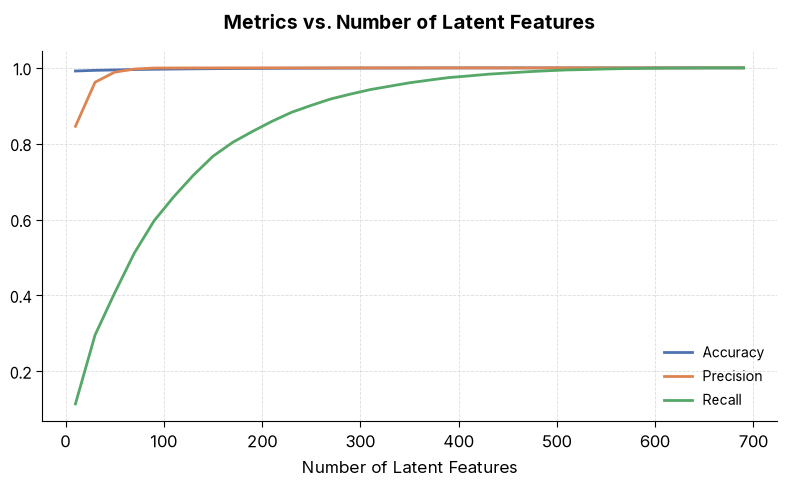

In [92]:
num_latent_feats = np.arange(10, 700+10, 20)
metric_scores = []

for k in num_latent_feats:
    # restructure with k latent features
    u_new, vt_new = u[:, :k], v[:k, :]
    
    # take dot product
    user_item_est = abs(np.around(np.dot(u_new, vt_new))).astype(int)
    # make sure the values are between 0 and 1
    user_item_est = np.clip(user_item_est, 0, 1)
    
    # total errors and keep track of them
    acc = accuracy_score(user_item.values.flatten(), user_item_est.flatten())
    precision = precision_score(user_item.values.flatten(), user_item_est.flatten())
    recall = recall_score(user_item.values.flatten(), user_item_est.flatten())
    metric_scores.append([acc, precision, recall])
    
    
plt.plot(num_latent_feats, metric_scores, label=['Accuracy', 'Precision', 'Recall'])
plt.legend()
plt.xlabel('Number of Latent Features')
plt.title('Metrics vs. Number of Latent Features')

`4.` From the above, we can't really be sure how many features to use, because simply having a better way to predict the 1's and 0's of the matrix doesn't exactly give us an indication of if we are able to make good recommendations. Given the plot above, what would you pick for the number of latent features and why?

**Provide your response here.**

I would choose **200 latent features as a starting point**. At approximately this level, the plot shows precision and accuracy close to 1 and recall around 0.85. This offers a reasonable compromise between a compact representation and recovering much of the observed interaction structure. Recall continues to improve with additional features, but the gains gradually diminish; there is no sharp elbow identifying a uniquely optimal choice.

These metrics measure reconstruction of the same user–article matrix used to fit the model, rather than the quality of recommendations for unseen interactions. Accuracy is also influenced by the large number of zeros in the matrix. Therefore, **200 is a provisional choice**, which should be compared with other feature counts using held-out interactions and recommendation metrics such as **Precision@K** (the proportion of the top K recommendations that are relevant) and **Recall@K** (the proportion of a user’s relevant articles retrieved within those top K recommendations).

`5.` Using 200 latent features and the values of U, S, and V transpose we calculated above, create an article id recommendation function that finds similar article ids to the one provide.

Create a list of 10 recommendations that are similar to article with id 4.  The function should provide these recommendations by finding articles that have the most similar latent features as the provided article.

In [155]:
def get_svd_similar_article_ids(article_id, vt, user_item=user_item, include_similarity=False):
    """
    INPUT:
    article_id - (int) an article id
    vt - (numpy array) vt matrix from SVD
    user_item - (pandas dataframe) matrix of users by articles: 
                1's when a user has interacted with an article, 0 otherwise
    include_similarity - (bool) whether to include the similarity in the output
    
    OUTPUT:
    article_ids - (list) a list of article ids that are in the same title cluster
    
    Description:
    Returns a list of the article ids similar using SVD factorization
    """
    # Find the index of the article_id
    article_idx = user_item.columns.get_loc(article_id)
    # Find the cosine similarity of all articles
    # Hint: vt should be transposed before passing to cosine_similarity to get a 714 x 714 matrix 
    cos_sim = cosine_similarity(vt.T, vt.T)
    scores = list(enumerate(cos_sim[article_idx]))

    # Get similarities only for the cos_sim of the article_idx
    # Sort and return the articles, don't include the own article

    scores = [pair for pair in scores if pair[0] != article_idx]
    scores = sorted(scores, key=lambda pair: pair[1], reverse=True)

    print("Top five (original column position, similarity) pairs:")
    print(scores[:5])

    # Translate positions into article IDs
    most_similar_items = [
        user_item.columns[position] for position, score in scores
    ]

    if include_similarity:
        return [[user_item.columns[position], score]
            for position, score in scores]

    return most_similar_items

In [156]:
# Recalculate recommendations using exactly 200 latent features.
vt_new = v[:200, :]
rec_articles = get_svd_similar_article_ids(
    4, vt_new, user_item=user_item
)[:10]

print("Shape:", vt_new.shape)
print("Recommendations:", rec_articles)

Top five (original column position, similarity) pairs:
[(552, np.float64(0.38128838796668796)), (454, np.float64(0.37485649597141013)), (219, np.float64(0.3548168224305347)), (554, np.float64(0.3537028396133)), (84, np.float64(0.3423228048256088))]
Shape: (200, 714)
Recommendations: [np.int64(1199), np.int64(1068), np.int64(486), np.int64(1202), np.int64(176), np.int64(1120), np.int64(244), np.int64(793), np.int64(58), np.int64(132)]


In [149]:
# Inspect SVD similarity pairs for article 4 using 200 latent features.
article_id = 4
vt = vt_new

article_idx = user_item.columns.get_loc(article_id)
cos_sim = cosine_similarity(vt.T, vt.T)
scores = list(enumerate(cos_sim[article_idx]))

print("Article column position:", article_idx)
print("Similarity matrix shape:", cos_sim.shape)
print("First five (position, score) pairs:", scores[:5])

Article column position: 2
Similarity matrix shape: (714, 714)
First five (position, score) pairs: [(0, np.float64(0.04339158468628752)), (1, np.float64(0.012963547194716388)), (2, np.float64(1.0)), (3, np.float64(0.059761929651507444)), (4, np.float64(-0.03568747997303259))]


In [150]:
# Create a vt_new matrix with 200 latent features
k = 200
vt_new = v[:k, :]

In [151]:
# What is the article name for article_id 4?
print("Current article:", get_article_names([4], df=df)[0])

Current article: analyze ny restaurant data using spark in dsx


In [152]:
# What are the top 10 most similar articles to article_id 4?
rec_articles = get_svd_similar_article_ids(4, vt_new, user_item=user_item)[:10]
rec_articles

[np.int64(1199),
 np.int64(1068),
 np.int64(486),
 np.int64(1202),
 np.int64(176),
 np.int64(1120),
 np.int64(244),
 np.int64(793),
 np.int64(58),
 np.int64(132)]

In [153]:
# What are the top 10 most similar articles to article_id 4?
get_article_names(rec_articles, df=df)

['country statistics: crude oil - exports',
 'airbnb data for analytics: athens reviews',
 'use spark r to load and analyze data',
 'country statistics: crude oil - proved reserves',
 'top analytics tools in 2016',
 'airbnb data for analytics: paris calendar',
 'notebooks: a power tool for data scientists',
 '10 powerful features on watson data platform, no coding necessary',
 'advancements in the spark community',
 'collecting data science cheat sheets']

In [154]:
assert set(rec_articles) == {1199, 1068, 486, 1202, 176, 1120, 244, 793, 58, 132}, "Oops! Your the get_svd_similar_article_ids function doesn't work quite how we expect."
print("That's right!  Great job!")

That's right!  Great job!


`6.` Use the cell below to comment on the results you found in the previous question. Given the circumstances of your results, discuss what you might do to determine if the recommendations you make above are an improvement to how users currently find articles, either by Sections 2, 3, or 4? Add any tradeoffs between each of the methods, and how you could leverage each type for different situations including new users with no history, recently new users with little history, and users with a lot of history. 

**Your response here.**

The SVD recommender produced the expected ten article IDs for article 4 and passed the supplied test. This confirms agreement with the project’s reference output, but it does not establish that the recommendations are useful to users or better than the other methods. SVD identifies similarities in interaction patterns, which may reveal relationships that article titles alone do not capture.

To compare the approaches, I would withhold some interactions from training and evaluate whether each method recommends those held-out articles. **Precision@K** would measure the proportion of the top K recommendations that are relevant, while **Recall@K** would measure the proportion of held-out relevant articles retrieved. The comparison should use the same evaluation conditions and examine users with different amounts of history. I would also consider catalog coverage and diversity, since accurate recommendations can still concentrate too heavily on popular articles. An online A/B test could then compare engagement with the current recommendation approach, using measures such as click-through rate, meaningful reading activity, and return visits. Recorded interactions are only a proxy for satisfaction.

Each method offers different advantages and limitations:

- **Rank-based recommendations** are simple and work without personal history, making them a useful starting point for new users. However, they offer little personalization and favor already-popular articles.
- **User-user collaborative filtering** personalizes recommendations using similar users’ histories. It becomes more informative as shared interactions accumulate, but sparse histories limit its usefulness, and computing similarities can be expensive.
- **Content-based recommendations** can suggest related articles after a user selects just one article or topic. They can also accommodate new articles with suitable text, although short titles provide limited context and same-cluster recommendations may lack variety.
- **SVD-based recommendations** represent broader interaction patterns through compact latent features. They can uncover less obvious article relationships, but depend on interaction data, are harder to explain, and require model updates as the catalog and behaviour change.

For **users with no history**, I would begin with popular articles and optionally ask about topic preferences. For **users with little history**, I would combine content recommendations based on their initial selections with a popularity fallback. For **users with substantial history**, I would emphasize collaborative and SVD-based recommendations while retaining content-based suggestions for variety. A hybrid approach could adjust these contributions as evidence accumulates, exclude previously seen articles, and be evaluated against the simpler baselines.

<a id='conclusions'></a>
### Extras
Using your workbook, you could now save your recommendations for each user, develop a class to make new predictions and update your results, and make a flask app to deploy your results.  These tasks are beyond what is required for this project.  However, from what you learned in the lessons, you certainly capable of taking these tasks on to improve upon your work here!


## Conclusion

> Congratulations!  You have reached the end of the Recommendation Systems project! 

> **Tip**: Once you are satisfied with your work here, check over your report to make sure that it is satisfies all the areas of the [rubric](https://review.udacity.com/#!/rubrics/2322/view). You should also probably remove all of the "Tips" like this one so that the presentation is as polished as possible.


## Directions to Submit

> Before you submit your project, you need to create a .html or .pdf version of this notebook in the workspace here. To do that, run the code cell below. If it worked correctly, you should get a return code of 0, and you should see the generated .html file in the workspace directory (click on the orange Jupyter icon in the upper left).

> Alternatively, you can download this report as .html via the **File** > **Download as** submenu, and then manually upload it into the workspace directory by clicking on the orange Jupyter icon in the upper left, then using the Upload button.

> Once you've done this, you can submit your project by clicking on the "Submit Project" button in the lower right here. This will create and submit a zip file with this .ipynb doc and the .html or .pdf version you created. Congratulations! 

In [ ]:
from subprocess import call
call(['python', '-m', 'nbconvert', 'Recommendations_with_IBM.ipynb'])